Level 0: Baseline Model

Axes of Variation

1. **Number of traders:** 1.
2. **Strategy switching:** No switching. The trader follows one fixed, deterministic strategy.
3. **Number of strategies:** 1.
4. **Strategy:** One-day momentum.
5. **Firm policy:** Evaluate returns only. No quorum, capital reallocation, hiring, or firing.
6. **Market history:** Fixed historical SPY data from 2024.
7. **Added market shocks:** None. The historical price fluctuations remain unchanged.
8. **Strategy lookback:** One trading-day return, calculated from two consecutive completed closing prices.
9. **Market-price independence:** The firm's trades do not affect market prices.

Trading Strategy - One Day Momentum

1. **Basic idea:** The trader follows the direction of the previous trading day's closing-price change.
2. **Positive price change:** If the previous close was higher than the close before it, buy using all available cash or hold if already invested.
3. **Negative price change:** If the previous close was lower than the close before it, sell all owned shares or remain in cash.
4. **No price change:** If the two closes were equal, keep the current position.
5. **Execution timing:** Use the two most recent completed closing prices to decide what to do at the next trading day's open. Execute trades at that opening price.
6. **Information restriction:** Today's closing price cannot influence today's opening trade.
7. **Holding period:** Positions remain in place, including overnight, until a later signal changes them.


Portfolio and Firm Rules

1. **Starting capital:** The firm begins with $10,000, allocated entirely to its single trader.
2. **Starting position:** The trader begins with $10,000 in cash and zero shares.
3. **Capital allocation:** When additional traders are introduced, the same initial firm capital will be divided equally among them.
4. **Position size:** Purchases use all available cash. Sales liquidate the entire position. Fractional shares are allowed.
5. **Allowed actions:** Buy, sell, or hold. Traders can sell only shares they already own.
6. **Restrictions:** No short selling, borrowing, or leverage.
7. **Costs and income:** Transaction costs, slippage, dividends, and cash interest are excluded.
8. **Price data:** Use SPY opening and closing prices without dividend adjustments.
9. **Firm behavior:** The firm observes and evaluates trader performance without influencing trading decisions.
10. **Final position:** Remaining shares are valued at the final 2024 closing price without forcing a sale.

Performance Evaluation

1. **Trader portfolio value:** At each trading day's close, add the trader's cash to the closing market value of their shares.

   $$
   V_i(t) = C_i(t) + Q_i(t)P(t)
   $$

   - $V_i(t)$: Trader $i$'s portfolio value at time $t$
   - $C_i(t)$: Trader $i$'s cash at time $t$
   - $Q_i(t)$: Trader $i$'s shares at time $t$
   - $P(t)$: SPY's closing price at time $t$

2. **Trader cumulative return:** Divide the gain or loss by the trader's initial capital, then multiply by 100.

   $$
   R_i(t) =
   \frac{V_i(t) - V_i(0)}{V_i(0)}
   \times 100
   $$

   For this model $V_i(0)$ = $10,000.

3. **Firm portfolio value:** Add the portfolio values of all traders.

   $$
   V_{\text{firm}}(t) = \sum_{i=1}^{N} V_i(t)
   $$

   Here, $N$ is the number of traders.

4. **Firm cumulative return:** Divide the firm's total gain or loss by its initial $10,000, then multiply by 100.

   $$
   R_{\text{firm}}(t) =
   \frac{V_{\text{firm}}(t) - 10{,}000}{10{,}000}
   \times 100
   $$

5. **Level 0 relationship:** Trader and firm returns are identical because the single trader manages all firm capital.

In [1]:
%pip install yfinance pandas matplotlib


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from importlib.metadata import version

import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import display

STARTING_CASH = 10_000.0
START_DATE = "2024-01-01"
END_DATE = "2024-12-31"

data_folder = Path("data")
data_folder.mkdir(exist_ok=True)
data_file = data_folder / "spy_2024_with_warmup.csv"

# Reuse our saved prices so repeated runs use the same data
if data_file.exists():
    prices = pd.read_csv(data_file, index_col="Date", parse_dates=True)

else:
    prices = yf.download(
        "SPY",
        start="2023-12-28",  # Include two earlier closes for our first signal
        end="2025-01-01",  # The download excludes this end date
        auto_adjust=False,  # Keep prices without dividend adjustments
        multi_level_index=False,
        progress=False,
    )

    if prices is None or prices.empty:
        raise ValueError("No prices downloaded. Check your connection and retry.")

    prices = prices[["Open", "Close"]].copy()
    prices.index.name = "Date"

    # Save the prices and use that saved copy on this run too
    prices.to_csv(data_file)
    prices = pd.read_csv(data_file, index_col="Date", parse_dates=True)

    # Record package versions so we can recreate our setup
    packages = ["yfinance", "pandas", "matplotlib"]
    versions = "\n".join(f"{name}=={version(name)}" for name in packages)
    (data_folder / "package_versions.txt").write_text(versions)

display(prices.head())

,Open,Close
Date,,
2023-12-28,476.880005,476.690002
2023-12-29,476.489990,475.309998
2024-01-02,472.160004,472.649994
2024-01-03,470.429993,468.790009
2024-01-04,468.299988,467.279999


Simulation

In [3]:
def run_model(prices, starting_cash, start, end):
    # Check that our dates are unique and in chronological order
    if (
        prices.empty
        or not prices.index.is_unique
        or not prices.index.is_monotonic_increasing
    ):
        raise ValueError("Data must have unique dates in order.")

    # Stop if opening or closing prices are missing or nonpositive
    if (
        prices[["Open", "Close"]].isna().any().any()
        or (prices[["Open", "Close"]] <= 0).any().any()
    ):
        raise ValueError("Opening and closing prices must be present and positive.")

    # Use only the two closes known before each day's open
    price_changes = prices["Close"].shift(1) - prices["Close"].shift(2)
    days = prices.loc[start:end]

    if days.empty or price_changes.loc[days.index].isna().any():
        raise ValueError("We need evaluation data and two earlier closes.")

    cash = float(starting_cash)
    shares = 0.0

    records = []

    for date, day in days.iterrows():
        change = price_changes.loc[date]
        signal = 1 if change > 0 else -1 if change < 0 else 0
        action = "HOLD"

        # A positive signal puts all available cash into SPY
        if signal == 1 and cash > 0:
            shares = cash / day["Open"]
            cash = 0.0
            action = "BUY"

        # A negative signal sells only the shares we already own
        elif signal == -1 and shares > 0:
            cash = shares * day["Open"]
            shares = 0.0
            action = "SELL"

        # Otherwise we keep our current position, including overnight
        value = cash + shares * day["Close"]
        # Record portfolio values and cumulative percentage returns at the close
        records.append({
            "Date": date,
            "Open": day["Open"],
            "Close": day["Close"],
            "Signal": signal,
            "Action": action,
            "Cash": cash,
            "Shares": shares,
            "TraderValue": value,
            "FirmValue": value,  # With one trader, firm and trader values are identical
            "TraderReturnPct": 100 * (value - starting_cash) / starting_cash,
            "FirmReturnPct": 100 * (value - starting_cash) / starting_cash,
        })

    return pd.DataFrame(records).set_index("Date")

Verfication Example Mock

In [4]:
# Use made-up prices so we can check the trades and values by hand
example = pd.DataFrame({
    "Open": [100, 100, 100, 111, 120, 105, 102, 100, 125, 110],
    "Close": [100, 102, 110, 105, 100, 100, 110, 120, 115, 110],
})

example.index = pd.to_datetime([
    "2023-12-28", "2023-12-29",
    "2024-01-02", "2024-01-03", "2024-01-04", "2024-01-05",
    "2024-01-08", "2024-01-09", "2024-01-10", "2024-01-11",
])

check = run_model(example, STARTING_CASH, START_DATE, END_DATE)

expected_actions = [
    "BUY", "HOLD", "SELL", "HOLD", "HOLD", "BUY", "HOLD", "SELL"
]
expected_values = [
    11000, 10500, 12000, 12000, 12000, 14400, 13800, 13200
]

# Check every action and closing portfolio value against our hand calculations
assert check["Action"].tolist() == expected_actions
assert check["TraderValue"].round(2).tolist() == expected_values
assert round(check["TraderReturnPct"].iloc[-1], 2) == 32.0
assert check["TraderValue"].equals(check["FirmValue"])

# Changing today's close must not change today's opening purchase
changed_example = example.copy()
changed_example.loc["2024-01-02", "Close"] = 50
changed_check = run_model(changed_example, STARTING_CASH, START_DATE, END_DATE)
assert changed_check.iloc[0]["Shares"] == check.iloc[0]["Shares"]

# An unchanged signal must keep an existing position
flat_example = example.iloc[:4].copy()
flat_example["Close"] = [100, 102, 102, 102]
flat_check = run_model(flat_example, STARTING_CASH, START_DATE, END_DATE)
assert flat_check["Action"].tolist() == ["BUY", "HOLD"]

print("All checks passed.")
display(check[["Signal", "Action", "Cash", "Shares", "TraderValue"]])

All checks passed.


,Signal,Action,Cash,Shares,TraderValue
Date,,,,,
2024-01-02,1,BUY,0.0,100.0,11000.0
2024-01-03,1,HOLD,0.0,100.0,10500.0
2024-01-04,-1,SELL,12000.0,0.0,12000.0
2024-01-05,-1,HOLD,12000.0,0.0,12000.0
2024-01-08,0,HOLD,12000.0,0.0,12000.0
2024-01-09,1,BUY,0.0,120.0,14400.0
2024-01-10,1,HOLD,0.0,120.0,13800.0
2024-01-11,-1,SELL,13200.0,0.0,13200.0


2024 Model Level 0 Simulation

In [5]:
results = run_model(prices, STARTING_CASH, START_DATE, END_DATE)
final = results.iloc[-1]

summary = pd.DataFrame({
    "Final value ($)": [
        final["TraderValue"],
        final["FirmValue"],
    ],
    "Cumulative return (%)": [
        final["TraderReturnPct"],
        final["FirmReturnPct"],
    ],
}, index=["Momentum trader", "Firm"])

display(summary.round(2))
print("Purchases:", int(results["Action"].eq("BUY").sum()))
print("Sales:", int(results["Action"].eq("SELL").sum()))
display(results.reset_index().head(10).round(4))

# Save the full daily record so we can inspect individual trades later
results.to_csv(data_folder / "level_0_daily_results.csv")

,Final value ($),Cumulative return (%)
Momentum trader,11205.82,12.06
Firm,11205.82,12.06


Purchases: 58
Sales: 58


,Date,Open,Close,Signal,Action,Cash,Shares,TraderValue,FirmValue,TraderReturnPct,FirmReturnPct
0,2024-01-02,472.16,472.65,-1,HOLD,10000.0000,0.0000,10000.0000,10000.0000,0.0000,0.0000
1,2024-01-03,470.43,468.79,-1,HOLD,10000.0000,0.0000,10000.0000,10000.0000,0.0000,0.0000
2,2024-01-04,468.30,467.28,-1,HOLD,10000.0000,0.0000,10000.0000,10000.0000,0.0000,0.0000
3,2024-01-05,467.49,467.92,-1,HOLD,10000.0000,0.0000,10000.0000,10000.0000,0.0000,0.0000
4,2024-01-08,468.43,474.60,1,BUY,0.0000,21.3479,10131.7169,10131.7169,1.3172,1.3172
5,2024-01-09,471.87,473.88,1,HOLD,0.0000,21.3479,10116.3464,10116.3464,1.1635,1.1635
6,2024-01-10,474.16,476.56,-1,SELL,10122.3237,0.0000,10122.3237,10122.3237,1.2232,1.2232
7,2024-01-11,477.59,476.35,1,BUY,0.0000,21.1946,10096.0427,10096.0427,0.9604,0.9604
8,2024-01-12,477.84,476.68,-1,SELL,10127.6224,0.0000,10127.6224,10127.6224,1.2762,1.2762
9,2024-01-16,475.26,474.93,1,BUY,0.0000,21.3096,10120.5898,10120.5898,1.2059,1.2059


Return Plot Level 0

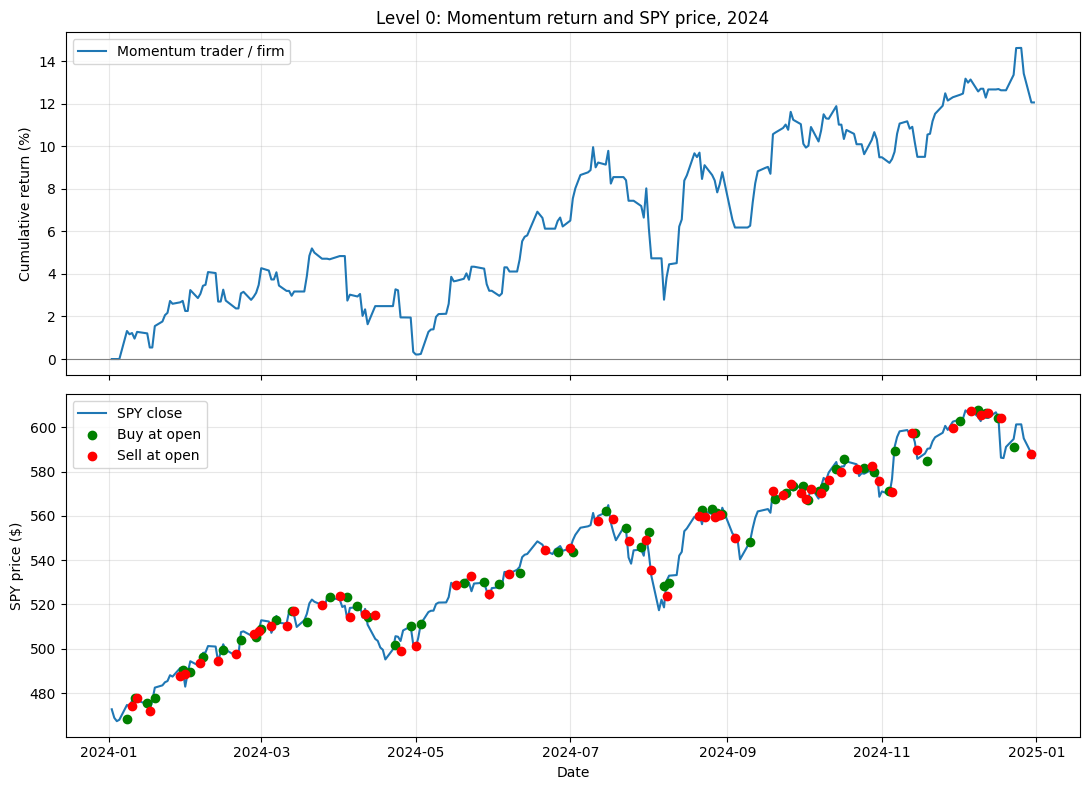

In [6]:
fig, (return_ax, price_ax) = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True
)

# Trader and firm returns share one line because they are identical in Level 0
return_ax.plot(
    results.index,
    results["TraderReturnPct"],
    label="Momentum trader / firm",
)
return_ax.axhline(0, color="gray", linewidth=0.8)
return_ax.set_title("Level 0: Momentum return and SPY price, 2024")
return_ax.set_ylabel("Cumulative return (%)")
return_ax.legend()
return_ax.grid(alpha=0.3)

price_ax.plot(results.index, results["Close"], label="SPY close")
buys = results[results["Action"] == "BUY"]
sells = results[results["Action"] == "SELL"]
# Dots show opening execution prices while the line shows closing prices
price_ax.scatter(buys.index, buys["Open"], color="green", label="Buy at open", zorder=3)
price_ax.scatter(sells.index, sells["Open"], color="red", label="Sell at open", zorder=3)
price_ax.set_xlabel("Date")
price_ax.set_ylabel("SPY price ($)")
price_ax.legend()
price_ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

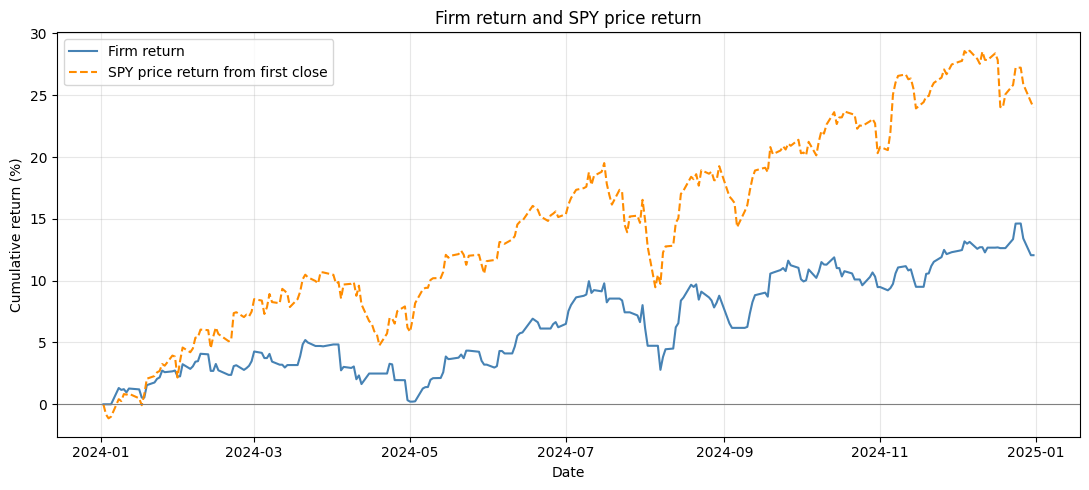

In [8]:
daily = results.copy()

if "Date" not in daily.columns:
    daily = daily.reset_index()

# Keep one firm observation per date
daily = daily.drop_duplicates("Date").sort_values("Date")

# Measure SPY's percentage change from the first closing price
spy_return = 100 * (daily["Close"] / daily["Close"].iloc[0] - 1)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    daily["Date"],
    daily["FirmReturnPct"],
    label="Firm return",
    color="steelblue",
)

ax.plot(
    daily["Date"],
    spy_return,
    label="SPY price return from first close",
    color="darkorange",
    linestyle="--",
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Firm return and SPY price return")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative return (%)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()